# 02 — Patch extraction from the original DICOM images

**What this notebook does.** For every mass in the three split files from notebook 01, it downloads the
original mammogram and the radiologist's outline from The Cancer Imaging Archive (TCIA), cuts a square patch
around the mass from both, saves them, and discards the large files. Only the patches are kept.

**Why the original DICOM images.** Copies of CBIS-DDSM circulating as JPEG have already been compressed once.
This project tests how the model copes with JPEG compression and other degradations, so the "clean" images
must be truly clean. Patches are saved as **16-bit PNG**, which is lossless.

**Input** (Kaggle: *Add Input*): the output of notebook 01 (`train.csv`, `val.csv`, `test.csv`).

**Output** (`/kaggle/working/patches`)

| File | Contents |
|---|---|
| `<roi_id>_img.png` | The mammogram patch, 16-bit, original pixel values |
| `<roi_id>_mask.png` | The matching outline (white = mass), same size and position |
| `patch_index.csv` | The split files plus the patch file names; read by notebooks 03 and 04 |
| `excluded.csv` | Masses that could not be processed, with the reason (empty in this run) |
| `_check_examples.png` | Eight patches with the outline drawn on top |

`roi_id` = list (Training/Test) + patient + breast + view + mass number, e.g. `Training_P_00001_LEFT_CC_1`.

**Settings.** Internet: On (images are downloaded from TCIA). No GPU needed. Run with
*Save Version → Save & Run All* so the outputs are kept. If the run stops, run it again: finished patches are skipped.

## 0. Setup
Imports and settings. `pydicom` reads DICOM files and is installed if missing.

| Setting | Value | Meaning |
|---|---|---|
| `MARGIN` | 0.25 | Space added around the mass on each side, as a share of the mass's size |
| `MIN_SIDE` | 64 px | Smallest patch |
| `MAX_SIDE` | 1,024 px | Larger patches are shrunk to this, to keep files small |
| `WORKERS` | 8 | Mammograms downloaded in parallel |
| `TCIA` | TCIA's public download service | Returns one image series as a zip file |

In [1]:
import os, io, glob, time, zipfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, requests
try:
    import pydicom
except ImportError:
    os.system("pip install -q pydicom"); import pydicom

SPLIT_DIR = os.environ.get("SPLIT_DIR") or str(next(Path("/kaggle/input").rglob("train.csv")).parent)
OUT = os.environ.get("OUT_DIR", "/kaggle/working/patches"); os.makedirs(OUT, exist_ok=True)
DICOM_DIR = os.environ.get("DICOM_DIR", "")      # only for testing with local files; leave empty on Kaggle
MARGIN, MIN_SIDE, MAX_SIDE, WORKERS = 0.25, 64, 1024, 8
TCIA = "https://services.cancerimagingarchive.net/nbia-api/services/v1/getImage"
print("Split files from:", SPLIT_DIR)

Split files from: /kaggle/input/datasets/abdussalamhameedat/output-data


## 1. Load the splits and pull out the image ID numbers
Each path in the case lists ends with `.../<series ID>/000000.dcm`. The series ID is what TCIA needs to send
that image. Three IDs are taken per mass: the full mammogram, the supplied crop and the outline.
The check `is_unique` makes sure no two masses get the same file name.

In [2]:
parts = []
for split in ("train", "val", "test"):
    d = pd.read_csv(os.path.join(SPLIT_DIR, f"{split}.csv")); d["split"] = split; parts.append(d)
df = pd.concat(parts, ignore_index=True)
series = lambda p: str(p).strip().split("/")[-2]
df["uid_full"] = df["image file path"].map(series)
df["uid_crop"] = df["cropped image file path"].map(series)
df["uid_mask"] = df["ROI mask file path"].map(series)
prefix = df["image file path"].str.split("_P_").str[0].str.replace("Mass-", "", regex=False)   # "Training" or "Test"
df["roi_id"] = (prefix + "_" + df["patient_id"] + "_" + df["left or right breast"] + "_"
                + df["image view"] + "_" + df["abnormality id"].astype(str))
assert df["roi_id"].is_unique, "Two rows got the same name"
print(df.groupby("split").size(), f"\n{df['uid_full'].nunique()} distinct mammograms to fetch")

split
test      378
train    1121
val       197
dtype: int64 
1592 distinct mammograms to fetch


**Result:** 1,696 masses (training 1,121, validation 197, test 378) on 1,592 distinct mammograms;
some mammograms contain more than one mass, and each is downloaded only once.

## 2. Download, cut and save
For each mammogram:

1. **Download** the full mammogram (`read_series`), retrying up to four times if the connection fails.
2. For each mass on it, **download the outline** and pick the file that is a true outline: only two pixel
   values (`is_mask`) and the same size as the mammogram. (The crop and outline files are not always in the same order.)
3. **Find the mass**: the white pixels of the outline.
4. **Cut a square** around it: the larger of its height and width, plus 25% on each side; at least 64 px;
   kept inside the image.
5. **Cut the same square from the outline**, so the patch and outline line up pixel for pixel. This is
   needed in the heatmap analysis to check whether the model looked at the mass.
6. **Save** both as PNG. The mammogram is then discarded.

Masses are grouped by mammogram (`groupby("uid_full")`) so each mammogram is downloaded once.

In [3]:
LOCAL = {}
if DICOM_DIR:
    for d_, _, files in os.walk(DICOM_DIR):
        if any(f.endswith(".dcm") for f in files): LOCAL[os.path.basename(d_)] = d_

def read_series(uid):
    """All images in one series as arrays (order not meaningful)."""
    if DICOM_DIR:
        return [pydicom.dcmread(f).pixel_array for f in sorted(glob.glob(os.path.join(LOCAL.get(uid, "_"), "*.dcm")))]
    for attempt in range(4):
        try:
            r = requests.get(TCIA, params={"SeriesInstanceUID": uid}, timeout=600); r.raise_for_status()
            z = zipfile.ZipFile(io.BytesIO(r.content))
            return [pydicom.dcmread(io.BytesIO(z.read(n))).pixel_array for n in sorted(z.namelist()) if n.lower().endswith(".dcm")]
        except Exception:
            time.sleep(5 * (attempt + 1))
    return []

def is_mask(im):
    sub = im[::4, ::4]
    return np.unique(sub).size <= 2 and sub.max() > 0           # an outline holds only two values

def out_paths(roi_id):
    return os.path.join(OUT, roi_id + "_img.png"), os.path.join(OUT, roi_id + "_mask.png")

def process(rows):
    """rows = every mass on one mammogram, so each mammogram is downloaded once."""
    status = {r.roi_id: "ok" for r in rows}
    todo = [r for r in rows if not all(os.path.exists(p) for p in out_paths(r.roi_id))]
    if not todo: return status
    imgs = read_series(todo[0].uid_full)
    if not imgs: return {**status, **{r.roi_id: "no_mammogram" for r in todo}}
    full = imgs[0]; H, W = full.shape
    for r in todo:
        cand = read_series(r.uid_mask) + ([] if r.uid_crop == r.uid_mask else read_series(r.uid_crop))
        masks = [m for m in cand if is_mask(m)]
        if not masks: status[r.roi_id] = "no_outline"; continue
        masks.sort(key=lambda m: (m.shape == full.shape, m.size), reverse=True)   # the full-size outline, not the small crop
        mask = (masks[0] > masks[0].max() / 2).astype(np.uint8) * 255
        if mask.shape != full.shape:
            mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST)
        ys, xs = np.where(mask > 0)
        if len(ys) == 0: status[r.roi_id] = "empty_outline"; continue
        side = int(max(np.ptp(ys) + 1, np.ptp(xs) + 1) * (1 + 2 * MARGIN))
        side = min(max(side, MIN_SIDE), H, W)
        cy, cx = (ys.min() + ys.max()) // 2, (xs.min() + xs.max()) // 2
        y0 = int(np.clip(cy - side // 2, 0, H - side)); x0 = int(np.clip(cx - side // 2, 0, W - side))
        p, m = full[y0:y0 + side, x0:x0 + side], mask[y0:y0 + side, x0:x0 + side]    # same square from both
        if side > MAX_SIDE:
            p = cv2.resize(p, (MAX_SIDE, MAX_SIDE), interpolation=cv2.INTER_AREA)
            m = cv2.resize(m, (MAX_SIDE, MAX_SIDE), interpolation=cv2.INTER_NEAREST)
        pi, pm = out_paths(r.roi_id); cv2.imwrite(pi, p); cv2.imwrite(pm, m)
    return status

groups = [list(g.itertuples()) for _, g in df.groupby("uid_full", sort=False)]
status, t0 = {}, time.time()
with ThreadPoolExecutor(WORKERS) as ex:
    for n, st in enumerate(ex.map(process, groups), 1):
        status.update(st)
        if n % 100 == 0 or n == len(groups):
            print(f"{n}/{len(groups)} mammograms, {(time.time() - t0) / 60:.1f} min", flush=True)
df["status"] = df["roi_id"].map(status)
print(df["status"].value_counts())

100/1592 mammograms, 0.7 min
200/1592 mammograms, 1.3 min
300/1592 mammograms, 2.0 min
400/1592 mammograms, 2.6 min
500/1592 mammograms, 3.3 min
600/1592 mammograms, 3.8 min
700/1592 mammograms, 6.2 min
800/1592 mammograms, 6.2 min
900/1592 mammograms, 6.2 min
1000/1592 mammograms, 6.7 min
1100/1592 mammograms, 7.3 min
1200/1592 mammograms, 8.0 min
1300/1592 mammograms, 8.7 min
1400/1592 mammograms, 9.2 min
1500/1592 mammograms, 9.9 min
1592/1592 mammograms, 10.5 min
status
ok    1696
Name: count, dtype: int64


**Result:** all 1,592 mammograms processed in about 10.5 minutes; status `ok` for all 1,696 masses.

## 3. Checks and the patch index
- Confirms the patches kept their 16-bit values, and reports the brightest pixel. A value near 65,535 means the
  images use the full 16-bit range, so converting to 8-bit later by dividing by 257 will not make them too dark.
- Saves `patch_index.csv` and `excluded.csv`.
- Shows the label counts per split, which must match notebook 01.

In [4]:
ok = df[df.status == "ok"].copy()
ok["img_path"] = ok["roi_id"] + "_img.png"; ok["mask_path"] = ok["roi_id"] + "_mask.png"
peak = max(int(cv2.imread(os.path.join(OUT, f), cv2.IMREAD_UNCHANGED).max()) for f in ok["img_path"].head(200))
dtype = cv2.imread(os.path.join(OUT, ok["img_path"].iloc[0]), cv2.IMREAD_UNCHANGED).dtype
print(f"Stored as {dtype}; brightest pixel in first 200 patches: {peak}")
ok.drop(columns="status").to_csv(os.path.join(OUT, "patch_index.csv"), index=False)
df[df.status != "ok"].to_csv(os.path.join(OUT, "excluded.csv"), index=False)
print(ok.groupby(["split", "label"]).size().unstack(), f"\nExcluded: {(df.status != 'ok').sum()}")
if (df.status != "ok").mean() > 0.05:
    print("More than 5% failed. Run the notebook again: only the missing ones are fetched.")

Stored as uint16; brightest pixel in first 200 patches: 65535
label    0    1
split          
test   231  147
train  589  532
val     92  105 
Excluded: 0


**Result:** stored as 16-bit; brightest pixel 65,535; 0 excluded. Label counts per split match notebook 01
(test 231/147, training 589/532, validation 92/105 benign/malignant).

## 4. Visual check: does the outline sit on the mass?
Draws eight patches (four benign, four malignant) with the outline in green.

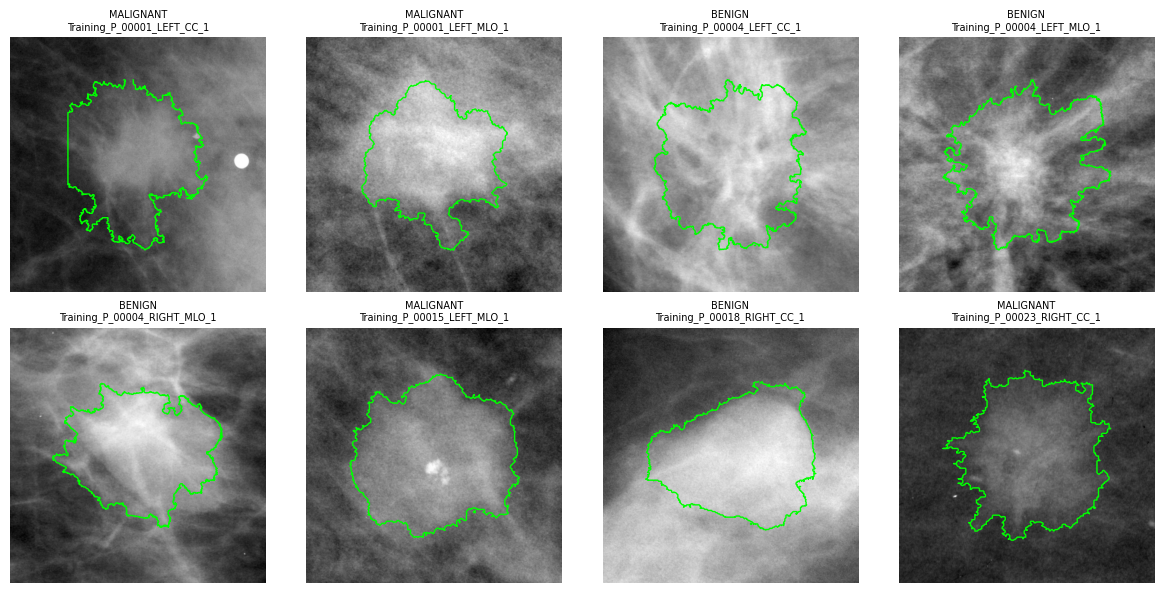

In [5]:
import matplotlib.pyplot as plt
show = ok.groupby("label").head(4)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for a, (_, r) in zip(ax.ravel(), show.iterrows()):
    im = cv2.imread(os.path.join(OUT, r.img_path), cv2.IMREAD_UNCHANGED).astype(float)
    mk = cv2.imread(os.path.join(OUT, r.mask_path), 0)
    a.imshow(im, cmap="gray")
    for c in cv2.findContours(mk, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
        a.plot(c[:, 0, 0], c[:, 0, 1], c="lime", lw=1)
    a.set_title(f"{r.pathology}\n{r.roi_id}", fontsize=7); a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "_check_examples.png"), dpi=120); plt.show()

**Result:** in all eight the outline sits on the mass, so the patch and outline are aligned.
Note that the outlines are hand-drawn and approximate: in the first example (`Training_P_00001_LEFT_CC_1`)
the outline has a straight left edge that leaves out part of the bright tissue. That edge is in the original
outline, not introduced here.

## Summary
1,696 patches extracted losslessly from the original DICOM images, none excluded, outlines aligned.
**Next:** notebook 03 attaches this notebook's output.